In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import kagglehub
import matplotlib.pyplot as plt


In [2]:
superSeed = 42
torch.manual_seed(superSeed)
np.random.seed(superSeed)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [4]:
# Data Loading and Preprocessing

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = df.drop("customerID",axis=1)
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce") # Conversion. This feature was initially stored as text in the dataset.
df = df.dropna()

y = df["Churn"].map({"Yes":1,"No": 0}).values
X = df.drop("Churn",axis=1)

numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
df[numeric_features] = df[numeric_features].apply(pd.to_numeric, errors="coerce")
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].mean())


categorical_features = df.drop(columns=["Churn"] + numeric_features).select_dtypes(include=["object"]).columns

print("Categorical Features: ", len(categorical_features))
print("Numerical Features: ", len(numeric_features))
df.head()


Categorical Features:  15
Numerical Features:  4


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Adding Label Encoder for Categorical Features
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

label_encoders = {}
X_cat= pd.DataFrame()
for column in categorical_features:
    label_encoder=LabelEncoder()
    X_cat[column]=label_encoder.fit_transform(X[column])
    label_encoders[column]=label_encoder

scaler=StandardScaler()
X_scaled= scaler.fit_transform(X[numeric_features])


# Train-Validation Split
X_cat_train, X_cat_val, X_num_train, X_num_val, y_train, y_val = train_test_split(
    X_cat.values, X_scaled, y, test_size=0.2, random_state=42, stratify=y)



In [6]:
# Dataset Class and Data Loaders
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

class TelcoDataset(Dataset):
    def __init__(self,X_cat,X_num,y):
        self.X_cat = torch.tensor(X_cat, dtype=torch.long)
        self.X_num=torch.tensor(X_num, dtype=torch.float32)
        self.y=torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self,xid):
        return self.X_cat[xid],self.X_num[xid],self.y[xid]


train_df= TelcoDataset(X_cat_train, X_num_train, y_train)
val_df=TelcoDataset(X_cat_val, X_num_val, y_val)
train_dataloader=DataLoader(train_df, batch_size=64, shuffle=True)
val_dataloader=DataLoader(val_df,batch_size=64,shuffle=False)


In [7]:
# Creating Neural Network using PyTorch and Categorical Embedding

class TelcoNeuralNetwork(nn.Module):
    def __init__(self, embedding_sizes, number):

        super().__init__()
        self.cat_embeddings=nn.ModuleList([nn.Embedding(categories,dim)
        for categories, dim in embedding_sizes ])

        total_embeddings=sum(dim for _,dim in embedding_sizes)

        self.layers = nn.Sequential(
            nn.Linear(total_embeddings + number, 64),
            nn.ReLU(),

            nn.Linear(64,32),
            nn.ReLU(),

            nn.Linear(32,1)
        )

    def forward(self, X_cat, X_num):
        embeddings=[]

        for i,embedding in enumerate(self.cat_embeddings):
                embeddings.append(embedding(X_cat[:, i]))

        X_cat= torch.cat(embeddings, dim=1)
        X = torch.cat([X_cat,X_num],dim=1)

        return self.layers(X)

embedding_sizes = [
    (X_cat[col].nunique(), min(50, (X_cat[col].nunique() + 1) // 2))
    for col in categorical_features
]



Epoch 1/50 | Train Loss: 73.7556 | Val Loss: 16.2281 | Val Acc: 0.7193
Epoch 2/50 | Train Loss: 63.3227 | Val Loss: 16.2885 | Val Acc: 0.7022
Epoch 3/50 | Train Loss: 62.7145 | Val Loss: 16.0222 | Val Acc: 0.7356
Epoch 4/50 | Train Loss: 61.9955 | Val Loss: 16.0010 | Val Acc: 0.7299
Epoch 5/50 | Train Loss: 61.6985 | Val Loss: 16.0274 | Val Acc: 0.7221
Epoch 6/50 | Train Loss: 61.4271 | Val Loss: 16.0055 | Val Acc: 0.7193
Epoch 7/50 | Train Loss: 60.9503 | Val Loss: 16.0517 | Val Acc: 0.7221
Epoch 8/50 | Train Loss: 60.9970 | Val Loss: 16.1011 | Val Acc: 0.7363
Epoch 9/50 | Train Loss: 60.8008 | Val Loss: 16.2268 | Val Acc: 0.7619
Epoch 10/50 | Train Loss: 60.5350 | Val Loss: 16.0893 | Val Acc: 0.7100
Epoch 11/50 | Train Loss: 60.4432 | Val Loss: 16.1330 | Val Acc: 0.7157
Epoch 12/50 | Train Loss: 60.4018 | Val Loss: 16.3392 | Val Acc: 0.7299
Epoch 13/50 | Train Loss: 60.0608 | Val Loss: 16.1412 | Val Acc: 0.7278
Epoch 14/50 | Train Loss: 59.9199 | Val Loss: 16.2648 | Val Acc: 0.7072
E

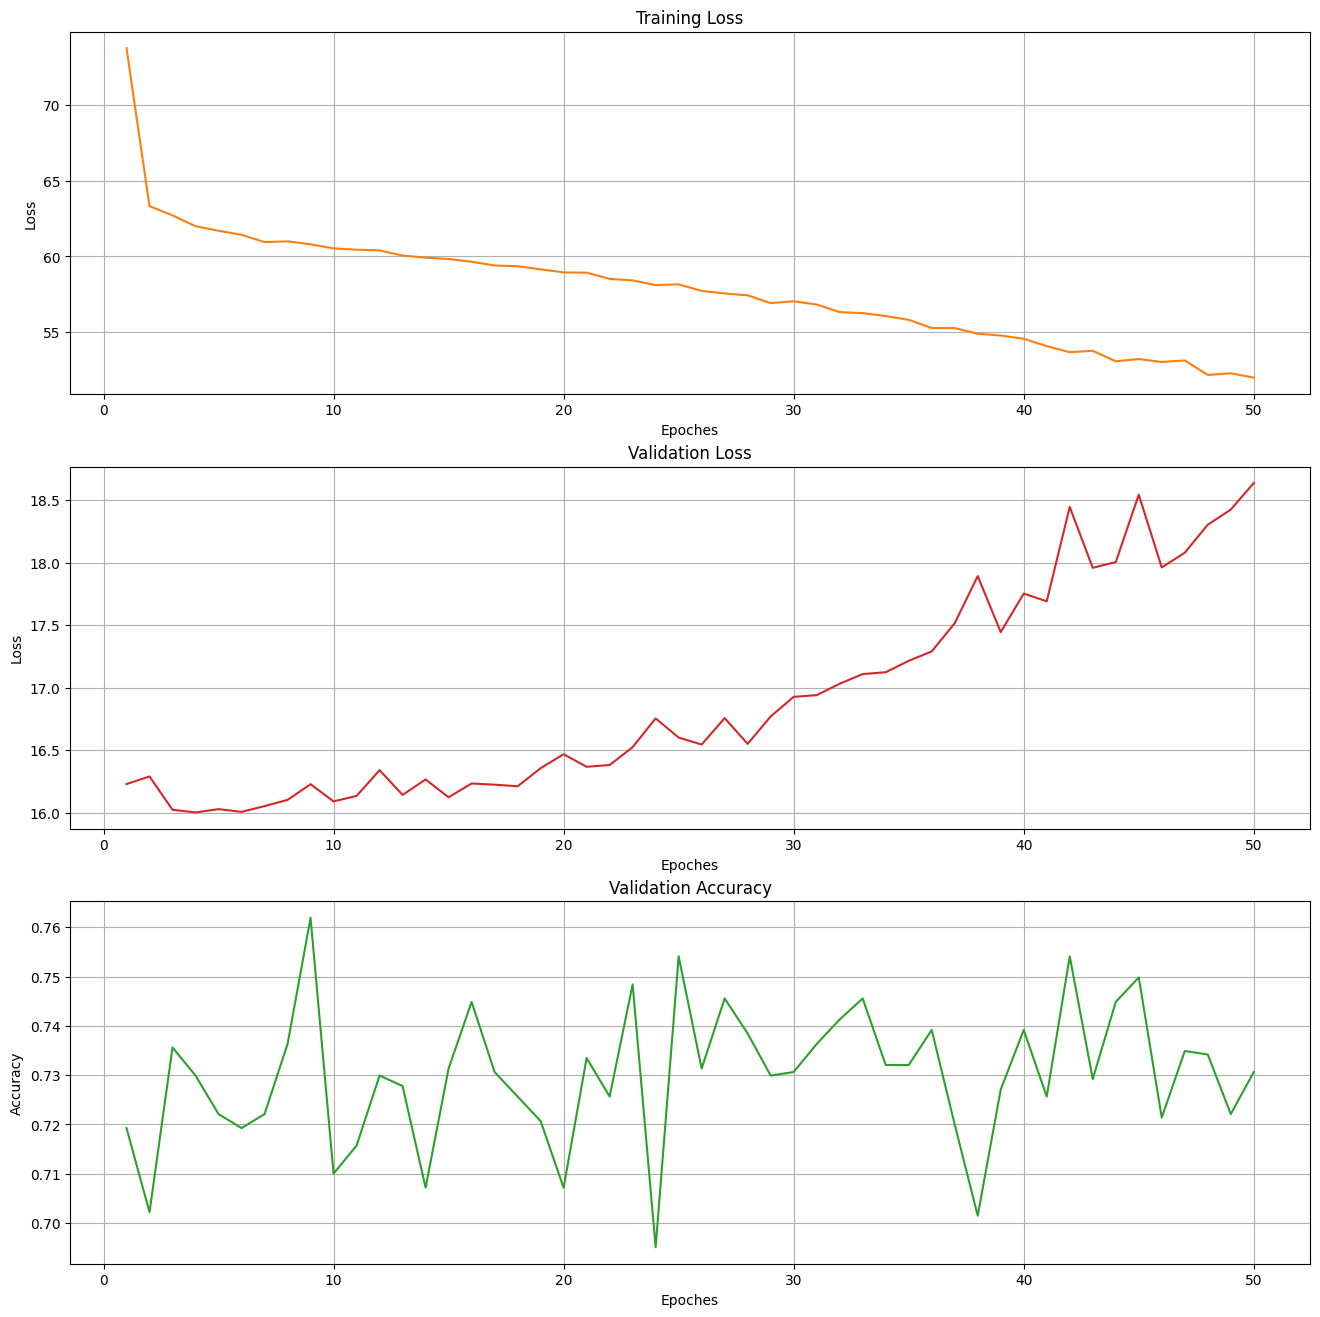

In [8]:
pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)
pos_weight = torch.tensor([pos_weight], dtype=torch.float32).to(device)

def pltLossAccGraph(epochArr=[], trainLossArr=[], valLossArr=[], valAccArr=[]):
    fig, (axTrainLoss, axValLoss, axAcc) = plt.subplots(3,figsize=(16,16))
    axTrainLoss.plot(epochArr,trainLossArr,'tab:orange')
    axTrainLoss.set_title('Training Loss')
    axTrainLoss.set_xlabel('Epoches')
    axTrainLoss.set_ylabel('Loss')
    axTrainLoss.grid(True)

    axValLoss.plot(epochArr,valLossArr,'tab:red')
    axValLoss.set_title('Validation Loss')
    axValLoss.set_xlabel('Epoches')
    axValLoss.set_ylabel('Loss')
    axValLoss.grid(True)

    axAcc.plot(epochArr,valAccArr,'tab:green')
    axAcc.set_title('Validation Accuracy')
    axAcc.set_xlabel('Epoches')
    axAcc.set_ylabel('Accuracy')
    axAcc.grid(True)

def train(model,train_dataloader, val_dataloader, device, epochs=50, lr=0.001):
    criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer=optim.Adam(model.parameters(), lr=lr)

    model=model.to(device)
    epochArr = []
    trainLossArr = []
    valLossArr = []
    valAccArr = []

    for epoch in range(epochs):
        model.train()
        train_loss=0

        for X_cat, X_num,y_batch in train_dataloader:
            X_cat= X_cat.to(device)
            X_num = X_num.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(X_cat, X_num)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for X_cat, X_num, y_batch in val_dataloader:
                X_cat = X_cat.to(device)
                X_num = X_num.to(device)
                y_batch = y_batch.to(device)

                y_pred = model(X_cat, X_num)
                loss = criterion(y_pred, y_batch)
                val_loss += loss.item()

                predicted = (torch.sigmoid(y_pred) >= 0.5).float()
                correct += (predicted == y_batch).sum().item()
                total += y_batch.size(0)

        accuracy = correct / total

        epochArr.append(epoch+1)
        trainLossArr.append(train_loss)
        valLossArr.append(val_loss)
        valAccArr.append(accuracy)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {accuracy:.4f}")
    pltLossAccGraph(epochArr, trainLossArr, valLossArr, valAccArr)


model = TelcoNeuralNetwork(
    embedding_sizes=embedding_sizes,
    number=len(numeric_features)
)

train(model, train_dataloader, val_dataloader, device)
